## **Ejercicio 1:**

 En el siguiente modelo indicar:

 i. ¿cuál es el modelo lineal?

 ii. ¿cuál el likelihood?

 iii. ¿cuantos parámetros hay en la distribución a posteriori?

$$
\begin{aligned}
y &\sim Normal(\mu, \epsilon) \\
\mu &= \alpha + \beta x \\
\alpha &\sim Normal(0, 10) \\
\beta &\sim Normal(0, 1) \\
\epsilon &\sim HalfNormal(25) \\
\end{aligned}
$$




## **Ejercicio 2:**

Se desea estudiar la relación entre la potencia de un automóvil (en HP) y su consumo de combustible (en km/L). Se propone el siguiente modelo de regresión lineal bayesiana:

$$ y_i \sim \mathcal{N}(\mu_i,\sigma) $$

donde

$$ \mu_i = \alpha + \beta x_i, $$

siendo $y_i$ el consumo de combustible y $x_i$ la potencia del automóvil.

Se consideran las siguientes distribuciones a priori:

$$ \alpha \sim \mathcal{N}(20,10) $$ $$ \beta \sim \mathcal{N}(-0.05,0.05) $$ $$ \sigma \sim \text{HalfNormal}(5). $$

A partir de los datos disponibles, ajuste el modelo y obtenga las distribuciones posteriores de los parámetros. Interprete los parámetros $\alpha$ y $\beta$.


## **Ejercicio 3:**

Para cuatro nuevos automóviles se conoce únicamente su potencia, que es de 80, 120, 160 y 200 HP, respectivamente. Utilizando el modelo ajustado en el punto anterior, obtenga la distribución predictiva del consumo de combustible para cada automóvil. Para cada caso, informe la mediana y un intervalo de credibilidad del 50% y del 89%.

## **Ejercicio 4: (Guiado) Regresión por cuantiles**

La **regresión por cuantiles** permite estudiar cómo se relacionan las variables explicativas con distintos puntos de la distribución de la variable respuesta, en lugar de centrarse únicamente en su media.

Podemos, por ejemplo, modelar la **mediana** $(q=0.5)$, el primer cuartil $q=0.25)$ o un cuantil superior como $q=0.9$. De esta manera, podemos analizar si la relación entre las variables cambia según la región de la distribución que nos interese.

Para ello, utilizaremos como *likelihood* la **distribución asimétrica de Laplace**, cuyo parámetro $q\in[0,1]$ determina el cuantil que queremos modelar. En particular, cuando $q=0.5$, la distribución se centra en la **mediana**.

A continuación, ajustaremos modelos para distintos valores de $q$ y observaremos cómo cambia la relación estimada entre las variables a medida que nos desplazamos hacia diferentes partes de la distribución.


(Requiere la carga del dataset de bebés)

In [ ]:
q = np.array([0.05, 0.5, 0.95])
for q_i, mu in zip(q, [0, 0, -1]):
    pz.AsymmetricLaplace(mu=mu, b=1, q=q_i).plot_pdf(support=(-6, 6))

Al utilizar una distribución Asimétrica de Laplace como *likelihood*, ¿estamos suponiendo necesariamente que la variable respuesta sigue exactamente esta distribución? ¿Qué otra interpretación podemos darle a su utilización en un modelo de regresión?

Para explorar esta idea, trabajaremos nuevamente con el conjunto de datos de **longitudes de bebés**.

En este caso, ajustaremos modelos para tres cuantiles diferentes:

$$
q=0.05,\qquad q=0.50,\qquad q=0.95.
$$

**1.** Ajuste un modelo de regresión por cuantiles para cada uno de estos valores de $q$.

**2.** ¿Qué representa cada uno de los cuantiles considerados? ¿Qué diferencia existe entre modelar $q=0.05$, $q=0.50$ y $q=0.95$?

**3.** Compare las relaciones estimadas entre la **edad** y la **longitud** para los tres cuantiles. ¿La relación entre ambas variables es la misma en toda la distribución?

**4.** A partir de los resultados obtenidos, ¿cómo interpretaría el uso de la distribución Asimétrica de Laplace en este contexto? ¿Es necesario pensar que la variable respuesta sigue exactamente esta distribución?





Datos:

In [ ]:
y_con = np.stack([datos.Longitud.values]* 3).T
x_con = np.stack([datos.Meses.values]* 3).T

Modelo:

In [ ]:
with pm.Model() as model_q:
    α = pm.Normal('α', 50, 3, shape=3)
    β = pm.Normal('β', 0, 5, shape=3)
    σ = pm.HalfNormal('σ', 5)

    μ = pm.Deterministic('μ', α + β * x_con**0.5)

    y_pred = pm.AsymmetricLaplace('y_pred',  mu=μ, b=σ, q=q, observed=y_con)

    idata_q = pm.sample(random_seed=123)

Output()

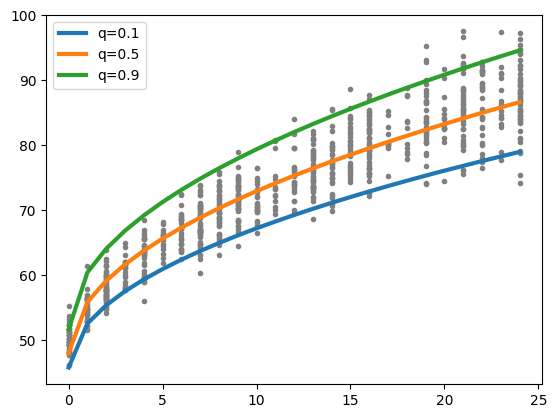

In [ ]:
plt.plot(datos.Meses, datos.Longitud, ".", color="0.5")
for idx, label in enumerate(("q=0.1", "q=0.5", "q=0.9")):
    plt.plot(datos.Meses.values, idata_q.posterior["μ"].mean(("chain", "draw"))[:,idx],
            label=label, lw=3);

plt.legend();

## **Ejercicio 5:**

COmpare los resultados del Ejercicio 4 con los obtenidos en un ajuste de un modelo de**regresión lineal con likelihood Normal**, utilizando la misma variable respuesta y la misma transformación de la edad que en los modelos anteriores.

Una vez ajustado el modelo, represente en el mismo gráfico:

* la media posterior $\mu$;
* los cuantiles aproximados $q=0.05$ y $q=0.95$ obtenidos a partir de la distribución Normal;
* las curvas estimadas mediante la regresión por cuantiles para $q=0.05$, $q=0.50$ y $q=0.95$.

**a.** ¿Cómo se obtienen los cuantiles $q=0.05$ y $q=0.95$ a partir de la media y la desviación estándar del modelo Normal?

**b.** Observe las curvas obtenidas. ¿Qué diferencia encuentra entre la forma en que el modelo Normal y la regresión por cuantiles representan los distintos niveles de la distribución?

**c.** ¿Las curvas correspondientes a los cuantiles $q=0.05$, $q=0.50$ y $q=0.95$ se encuentran necesariamente a la misma distancia de la mediana? ¿Qué puede decir esto sobre la simetría de la distribución condicional?

**d.** Observe cómo se separan las curvas a medida que aumenta la edad. ¿Qué información proporciona esto sobre la variabilidad de la longitud? ¿Cómo podría representar esta característica la regresión por cuantiles?

Modelo:

In [ ]:
with pm.Model() as model_n:
    α = pm.Normal('α', 50, 3)
    β = pm.Normal('β', 0, 5)
    σ = pm.HalfNormal('σ', 5)

    μ = pm.Deterministic('μ', α + β * datos.Meses.values**0.5)

    y_pred = pm.Normal('y_pred',  μ, σ, observed=datos.Longitud.values)

    idata_n = pm.sample(random_seed=123)

Output()

## **Ejercicio 6: Regresión Lineal Jerárquica (para resolver en clase)**

Explorar cómo es posible aplicar el mismo concepto de jerarquización a modelos de regresión lineal, para realizar inferencias a nivel de subgrupo y a nivel global.


Datos:

In [ ]:
N = 20
grupos = ["A", "B", "C", "D", "E", "F", "G", "H"]

M = len(grupos)

idx = np.repeat(range(M - 1), N)
idx = np.append(idx, 7)

np.random.seed(314)

alpha_real = np.random.normal(2.5, 0.5, size=M)
beta_real = np.random.beta(6, 1, size=M)
eps_real = np.random.normal(0, 0.5, size=len(idx))

y_m = np.zeros(len(idx))
x_m = np.random.normal(0, 1, len(idx))
y_m = alpha_real[idx] + beta_real[idx] * x_m + eps_real

_, ax = plt.subplots(2, 4, figsize=(10, 5), sharex=True, sharey=True)
ax = np.ravel(ax)
j, k = 0, N

for i, g in enumerate(grupos):
    ax[i].scatter(x_m[j:k], y_m[j:k], marker=".")
    ax[i].set_title(f"grupo {g}")
    j += N
    k += N


Modelo:

In [ ]:
coords = {"grupo": grupos}

with pm.Model(coords=coords) as modelo_jerárquico:
    α_μ = pm.Normal("α_μ", mu=y_m.mean(), sigma=1)
    α_σ = pm.HalfNormal("α_σ", 5)
    β_μ = pm.Normal("β_μ", mu=0, sigma=1)
    β_σ = pm.HalfNormal("β_σ", sigma=5)

    α = pm.Normal("α", mu=α_μ, sigma=α_σ, dims="grupo")
    β = pm.Normal("β", mu=β_μ, sigma=β_σ, dims="grupo")
    σ = pm.HalfNormal("σ", 5)
    _ = pm.Normal(
        "y_pred",
        mu=α[idx] + β[idx] * x_m,
        sigma=σ,
        observed=y_m
    )

    idata_mj = pm.sample(random_seed=123)


### **1.** Reparametrización y divergencias

Compare los resultados obtenidos con la parametrización centrada y la no centrada.

* ¿Qué diferencia observa en la geometría de las distribuciones posteriores?
* ¿Cómo se relaciona esta diferencia con la presencia de divergencias?
* ¿Por qué la parametrización no centrada puede facilitar el muestreo?

### **2.** Información disponible por grupo

Observe las estimaciones posteriores de $\alpha$ y $\beta$ para los distintos grupos.

* ¿Qué grupo presenta mayor incertidumbre en sus parámetros?
* ¿Cómo se relaciona esta incertidumbre con la cantidad de observaciones disponibles para ese grupo?
* ¿Qué papel cumple la estructura jerárquica cuando un grupo tiene pocos datos?

### **3.** Partial pooling

Observe las rectas ajustadas para los ocho grupos, prestando especial atención al grupo H, que cuenta con una única observación.

* ¿Cómo es posible obtener una estimación de su pendiente e intercepto a pesar de contar con tan poca información?
* ¿Qué información aporta el resto de los grupos a la estimación de H?
* Explique con sus palabras qué significa que el modelo realice **partial pooling**.


## **Ejercicio 7: (guiado) Relación no lineal**

Hasta ahora hemos utilizado modelos lineales para describir la relación entre una variable respuesta y uno o más predictores. Sin embargo, ¿qué ocurre cuando la relación entre ambas variables no puede describirse adecuadamente mediante una recta?

Trabajaremos nuevamente con los datos de **longitudes de bebés**, considerando la edad en meses como variable explicativa y la longitud como variable respuesta.

### **1.** Realice un gráfico de dispersión entre `Meses` y `Longitud`.

**a.** ¿Considera razonable suponer una relación lineal entre ambas variables?

**b.** ¿Qué características de los datos sugieren que podría ser conveniente utilizar un modelo más flexible?

Regresión polinomial

### **2. Considere el siguiente modelo:**

$$
y_i \sim \mathcal{N}(\mu_i,\sigma)
$$

con

$$
\mu_i =
\alpha +
\beta_1 x_i +
\beta_2 x_i^2 +
\beta_3 x_i^3.
$$

Ajuste el modelo utilizando como variable explicativa la edad y sus potencias hasta grado 3.

**a.** Represente la media posterior del modelo junto con los datos observados.

**b.** ¿La relación estimada permite capturar alguna curvatura que no podía representar el modelo lineal?

**c.** ¿Qué ocurre si aumenta el grado del polinomio? Pruebe, al menos, con un polinomio de grado 2 y otro de grado 4. Compare visualmente los ajustes.

### 3. Splines

Otra alternativa para modelar relaciones no lineales consiste en utilizar **splines**, que permiten construir una función flexible a partir de distintos tramos de la variable explicativa.

Considere ahora el siguiente modelo:

$$
y_i \sim \mathcal{N}(\mu_i,\sigma)
$$

$$
\mu_i = \alpha + \sum_{j=1}^{K}\beta_j B_j(x_i),
$$

donde $B_j(x)$ son las funciones base construidas a partir de los splines.

Ajuste un modelo utilizando una base de splines para la edad.

**a.** Represente la relación estimada entre edad y longitud.

**b.** Compare el ajuste obtenido con el del polinomio de grado 3.

**c.** ¿Qué ventajas y desventajas observa en cada alternativa?

**d.** ¿Qué ocurre al modificar la cantidad de grados de libertad utilizados para construir el spline?

### **4.** Compare los modelos mediante un criterio de comparación de modelos, como **LOO**.

¿Qué diferencias encuentra entre los modelos lineal, polinomial y spline?

A partir de los resultados obtenidos, ¿qué modelo utilizaría para representar la relación entre edad y longitud? Justifique su respuesta a partir de los resultados, no solamente de la apariencia del gráfico.


## **Ejercicio 8: (guiado) ¿Qué variables necesitamos?**

Trabajaremos con el conjunto de datos de **pingüinos**. Nuestro objetivo será modelar la **masa corporal** a partir de distintas características observadas en cada individuo.

Consideraremos como posibles predictores:

* longitud del pico;
* profundidad del pico;
* longitud de la aleta;
* sexo.

### **1.** Comience con el siguiente modelo:

$$
y_i \sim \mathcal{N}(\mu_i,\sigma)
$$

donde

$$
\mu_i =
\alpha +
\beta_1\,\text{bill_length}_i +
\beta_2\,\text{bill_depth}_i +
\beta_3\,\text{flipper_length}_i +
\beta_4\,\text{sex}_i.
$$

Ajuste el modelo y examine las distribuciones posteriores de los coeficientes.

**a.** ¿Qué información aporta cada coeficiente sobre la relación entre el predictor y la masa corporal?

**b.** ¿Hay variables cuyos efectos estén poco informados por los datos?

**c.** ¿Qué dificultades pueden aparecer cuando varias variables contienen información similar?


### **2.** Comparación de modelos

Construya modelos alternativos eliminando uno o más predictores.

Compare los modelos utilizando **LOO**.

**a.** ¿Cambian las conclusiones al eliminar alguna de las variables?

**b.** ¿Un modelo con más variables necesariamente presenta un mejor desempeño predictivo?

**c.** Compare el ajuste y la capacidad predictiva de los modelos.


### **3.** Selección de variables

**a.** Investigue sobre la herramienta **KULPRIT** para selección de variables. Explore con esta herramienta qué predictores presentan evidencia de ser relevantes para explicar la masa corporal y analice los resultados obtenidos.

**b.** ¿Qué variables aparecen como relevantes?

**c.** ¿Coincide esta selección con lo observado al comparar los modelos mediante LOO?

**d.** ¿Qué diferencias encuentra entre seleccionar variables a partir de sus coeficientes y evaluar modelos completos mediante un criterio predictivo?


### **4.** Ajuste del modelo

A partir de los análisis anteriores, ajuste un modelo final utilizando el conjunto de predictores que considere adecuado.

Compare sus predicciones con las observaciones mediante un **posterior predictive check**.

¿El modelo final reproduce razonablemente las características principales de los datos?
